# Nuclei with VQE: from the deuteron to helium

## The problem

The deuteron notebook found the energy of the simplest nucleus, a proton and a neutron. It worked because the two-body problem separates: only the *relative* motion remains, and that is one particle in a basis of oscillator states. A heavier nucleus does not separate like that. Tritium has three nucleons, helium-4 has four, and all of them are identical fermions of two kinds: **no two may occupy the same state**, and the wave function must change sign when two of them swap.

The language for this is **second quantization**. Instead of a wave function of $A$ coordinates, we list the single-nucleon states, the **orbitals**, and ask which are occupied. One orbital is one qubit: $|1\rangle$ occupied, $|0\rangle$ empty. The Pauli principle is built into the representation, because a qubit cannot hold two nucleons.

We keep the ingredients of the deuteron model: the first S-wave oscillator states $|p\rangle$ with $\hbar\omega = 7$ MeV, the same kinetic energy, and the same contact attraction $-V_0$ between nucleons in $|0\rangle$. Each nucleon can now be a proton or a neutron with spin up or down, so there are $4\times$ (number of oscillator states) orbitals. This is a **schematic** model: it shows how a many-nucleon problem becomes a circuit, not what a real nuclear calculation gives. We return to what it leaves out below.

The two choices that decided the deuteron result are still the ones to study:

- the **mapping**: how the orbitals and their creation and annihilation operators become qubits and Pauli strings;
- the **ansatz**: the family of states the circuit can reach. For a nucleus the ansatz must also keep the right numbers of protons and neutrons.

## The workflow

| Step | What it does | Code |
|---|---|---|
| 1. Operator | Build the nuclear Hamiltonian and map it to qubits | `ops.py` |
| 2. Encoding | Build the ansatzes | `encoding.py` |
| 3. Execution | Run the VQE loop for every pair | `execution.py` |
| 4. Analysis | Compare errors, cost and convergence, then change the nucleus | `analysis.py` |

The same steps run from the command line with `python nuclei/main.py`, started in `../scripts/`. The code lives in `../scripts/nuclei/` and is imported below, so each module can be read next to the step that uses it. Energies are in MeV.

## Setup

By default this notebook runs on the Aer simulator with exact energies (no shot noise), so the differences you see come from the mapping and the ansatz alone. Set `shots` to a number such as `4096` to add sampling noise.

- `nucleus`: a name from `ops.NUCLEI` (`"2H"`, `"3H"`, `"3He"`, `"4He"`, `"2n"`) or a pair `"Z,N"` of proton and neutron numbers.
- `n_orb`: oscillator states per kind of nucleon. The register has $4\,n_\text{orb}$ qubits, so this is the main cost knob.
- `reps`: layers of the hardware-efficient ansatz. `starts`: random starting points for the optimizer. `maxiter`: optimizer budget per start.
- `backend_name`: leave `None` for the simulator. A hardware run needs `shots > 0`, and it submits many jobs, so try one mapping and one ansatz first.

In [1]:
import sys
import tempfile
from pathlib import Path

import numpy as np
from IPython.display import Image
from qiskit.quantum_info import Statevector

# The nuclei code lives in ../scripts/nuclei.
# Run this notebook from its own folder (the Jupyter default).
sys.path.insert(0, str(Path("../scripts/nuclei").resolve()))

import analysis
import encoding as enc
import execution
import ops

%matplotlib inline

nucleus = "4He"  # a name from ops.NUCLEI, or "Z,N"
n_orb = 2  # oscillator states per kind of nucleon
backend_name = None  # None = Aer simulator
reps = 2
starts = 3
maxiter = 500
shots = 0  # 0 = exact energies (simulator only)

z, n = ops.parse_nucleus(nucleus)

## Step 1: The operator (the Hamiltonian)

### From nucleons to orbitals

The orbitals are the S-wave oscillator states $|p\rangle$, $p = 0, \dots, n_\text{orb}-1$, for each of the four kinds of nucleon: proton or neutron, spin up or down. Let $a^\dagger_{k,p}$ put a nucleon of kind $k$ into $|p\rangle$ and $a_{k,p}$ remove it. The Hamiltonian is

$$H = \sum_{k}\sum_{pq} t_{pq}\, a^\dagger_{k,p}\, a_{k,q} \;-\; V_0 \sum_{k<k'} n_{k,0}\, n_{k',0}, \qquad n_{k,p} = a^\dagger_{k,p} a_{k,p},$$

where $t$ is exactly the kinetic matrix of the deuteron notebook (tridiagonal, with $\langle p|T|p\rangle = \tfrac{\hbar\omega}{2}(2p+\tfrac32)$), and $V_0 = 5.687$ MeV is the same contact strength. The first term moves a nucleon between oscillator states. The second lowers the energy by $V_0$ for every pair of nucleons that sit in $|0\rangle$ together. All four kinds attract equally. In nuclear physics this is the **Wigner SU(4) limit**, a good first approximation to the strong force, which does not care whether a nucleon is a proton or a neutron or which way its spin points.

A nucleus is a choice of the proton number $Z$ and the neutron number $N$. The Hamiltonian never changes the number of nucleons of each kind, so each nucleus is a **sector**: the states with the right counts. We want the lowest energy in that sector. The **reference state** is the simplest filling: nucleons go into the lowest free orbitals, spin up and down alternately.

In [2]:
np.set_printoptions(precision=3, suppress=True, linewidth=120)
exact = ops.exact_energies(n_orb, z, n)
ref = ops.reference_occupation(z, n, n_orb)

print(f"{ops.nucleus_name(z, n)}: Z = {z}, N = {n}, {ops.n_modes(n_orb)} orbitals = {ops.n_modes(n_orb)} qubits")
print("\nOccupation of the reference state (one row per kind of nucleon):")
for k, kind in enumerate(ops.KINDS):
    print(f"  {kind:>7}: {ref[k * n_orb:(k + 1) * n_orb]}")

print(f"\nStates in this sector:       {exact['dimension']} (of {2 ** ops.n_modes(n_orb)} on the register)")
print(f"Exact energy in this basis   {exact['exact']:.6f} MeV")
print(f"Reference filling alone      {exact['ref']:.6f} MeV")
print(f"Unbound nucleons             {exact['free']:.6f} MeV")
print(f"Binding energy in the model  {exact['free'] - exact['exact']:.3f} MeV")

4He: Z = 2, N = 2, 8 orbitals = 8 qubits

Occupation of the reference state (one row per kind of nucleon):
     p_up: [1, 0]
   p_down: [1, 0]
     n_up: [1, 0]
   n_down: [1, 0]

States in this sector:       16 (of 256 on the register)
Exact energy in this basis   -16.116761 MeV
Reference filling alone      -13.119487 MeV
Unbound nucleons             12.864056 MeV
Binding energy in the model  28.981 MeV


Two things to notice. First, the sector is tiny: the register has $2^8 = 256$ states for $n_\text{orb}=2$, but only 16 of them hold two protons and two neutrons. The Pauli principle and the conserved particle numbers do most of the work of shrinking the problem, and an ansatz that respects them has far less to search.

Second, the **binding energy**. A nucleus is bound if it has less energy than the same nucleons kept apart. In this small oscillator basis, "apart" still costs the lowest one-nucleon energy (the oscillator's zero-point energy) per nucleon, so the unbound reference is $A\,\varepsilon_1$ with $\varepsilon_1$ the lowest eigenvalue of $t$. The binding energy is the difference. The table compares the nuclei of the model with the measured values.

In [3]:
measured = {"2H": 2.2246, "3H": 8.4818, "3He": 7.7181, "4He": 28.2957}  # MeV
print(f"{'nucleus':>7} {'qubits':>6} {'sector':>7} {'E exact':>9} {'binding':>8} {'measured':>9}")
for name, (zz, nn) in ops.NUCLEI.items():
    ex = ops.exact_energies(n_orb, zz, nn)
    m = f"{measured[name]:>9.3f}" if name in measured else f"{'-':>9}"
    print(f"{name:>7} {ops.n_modes(n_orb):>6} {ex['dimension']:>7} {ex['exact']:>9.3f} {ex['free'] - ex['exact']:>8.3f} {m}")

nucleus qubits  sector   E exact  binding  measured
     2n      8       4     2.135    4.297         -
     2H      8       4     2.135    4.297     2.225
     3H      8       8    -4.208   13.856     8.482
    3He      8       8    -4.208   13.856     7.718
    4He      8      16   -16.117   28.981    28.296


The binding energy of helium-4 comes out within a few percent of the measured 28.3 MeV, but that is partly luck: $V_0$ was fitted to the deuteron in a large basis, not to this one, and the model has no Coulomb repulsion or spin dependence. The deuteron is overbound (4.3 against 2.2 MeV) and the dineutron `2n`, which does not exist in nature, is exactly as bound as the deuteron. This follows from the SU(4) symmetry: the model cannot tell a neutron pair from a proton-neutron pair, and tritium and helium-3 are also degenerate. These failures are not bugs but the limits of a **schematic model**: the point of the notebook is the quantum-computing recipe, which stays the same when a better Hamiltonian replaces this one.

### From orbitals to qubits: the mapping

Fermion operators anticommute, $a_i a_j = -a_j a_i$, but operators on different qubits commute. A **fermion-to-qubit mapping** repairs the signs with a string of $Z$ gates that counts occupied orbitals. Two common ones:

| Mapping | Qubit $j$ stores | $a_j^\dagger$ acts as | Qubits |
|---|---|---|---|
| Jordan-Wigner (`jordan_wigner`) | the occupation of orbital $j$ | a $Z$ string over the qubits below $j$, then $(X - iY)/2$ on $j$ | one per orbital |
| Parity (`parity`) | the parity of the occupations of orbitals $0..j$ | an $X$ string over the qubits above $j$ (the parities that change), a $Z$ on $j-1$ for the sign, then $(X - iY)/2$ on $j$ | one per orbital |

The mappings differ in how local the operators are. Occupations are local in Jordan-Wigner and signs are not; in parity it is the other way round. They have the same eigenvalues, because they are only different ways to write the same operators.

In [4]:
for mapping in ops.MAPPINGS:
    H = ops.build_hamiltonian(n_orb, mapping, z, n, ops.PENALTY)
    weights = [sum(c != "I" for c in label) for label in H.paulis.to_labels()]
    energies = np.linalg.eigvalsh(H.to_matrix())
    print(
        f"{mapping:>13}: {H.num_qubits} qubits, {len(H):>2} Pauli terms, "
        f"max weight {max(weights)}, lowest energy {energies[0]:.6f} MeV"
    )

print("\nThe hopping term of the lowest proton orbitals (Jordan-Wigner and parity):")
for mapping in ops.MAPPINGS:
    up0 = ops.ladder(0, 8, mapping)
    up1 = ops.ladder(1, 8, mapping)
    print(f"{mapping:>13}:", (0.5 * (up0[0] @ up1[1] + up1[0] @ up0[1])).simplify())

jordan_wigner: 8 qubits, 27 Pauli terms, max weight 2, lowest energy -16.116761 MeV


       parity: 8 qubits, 27 Pauli terms, max weight 4, lowest energy -16.116761 MeV

The hopping term of the lowest proton orbitals (Jordan-Wigner and parity):
jordan_wigner: SparsePauliOp(['IIIIIIYY', 'IIIIIIXX'],
              coeffs=[0.25+0.j, 0.25+0.j])
       parity: SparsePauliOp(['IIIIIIZX', 'IIIIIIIX'],
              coeffs=[-0.25+0.j,  0.25+0.j])


## Stop and think: what is different from the deuteron?

1. **Qubits are orbitals now.** The deuteron needed $\log_2 N$ qubits for $N$ states, because one qubit state *labeled* one basis state. Here a qubit register holds a whole configuration of nucleons, one qubit per orbital. That is more qubits, but it is the cost of describing $A$ particles at all: a single wave function of $A$ coordinates grows exponentially, while the orbital description grows linearly in the number of orbitals.
2. **The printed lowest energy is the same in both mappings**, and equals the sector energy above. We added a *penalty* $30\,\text{MeV}\times\sum_k (N_k - N_k^\text{target})^2$ so that the lowest state of the *whole* register is the one with the right nucleon numbers. Without it, extra nucleons would lower the energy (the force is attractive), and an ansatz that can change particle numbers would use that. The penalty is zero on the sector, so it does not change the answer.
3. **The mapping changes the Pauli terms, not the physics.** The hop between the two lowest oscillator states of one kind is $\tfrac14(XX+YY)$ on neighboring qubits in Jordan-Wigner, because the orbitals $0$ and $1$ sit next to each other and the $Z$ string is empty. In parity the same hop is $\tfrac14(IX - ZX)$, a different pair of strings. Which mapping is cheaper depends on how the orbitals are laid out, and Jordan-Wigner becomes costly when orbitals that interact are far apart in the order.
4. **The Hamiltonian is not a tridiagonal matrix any more.** It is a sum of short Pauli strings that touch two or four qubits, plus the penalty terms. Counting the terms is counting the measurement settings, as before.

## Step 2: Encoding and ansatzes

An ansatz $|\psi(\boldsymbol\theta)\rangle = U(\boldsymbol\theta)|\text{start}\rangle$ defines which states the optimizer can reach, and by the variational principle its lowest energy bounds the truth from above. We compare four:

| Ansatz | Idea |
|---|---|
| `ref` | The reference filling. No angles. The baseline. |
| `uccs` | The reference followed by rotations $e^{\theta(a^\dagger_a a_i - a^\dagger_i a_a)}$ that move **one** nucleon between oscillator states of the same kind. |
| `uccsd` | The same, plus rotations that move **two** nucleons at once, $e^{\theta(a^\dagger_a a^\dagger_b a_j a_i - \text{h.c.})}$. |
| `hea_ref` | **Hardware-efficient**: layers of $R_Y$ and CX, started from the reference filling. Knows nothing about nucleons. |

`uccs` and `uccsd` are **unitary coupled cluster** ansatzes, borrowed from quantum chemistry. They are built from physical moves of nucleons and every one of them conserves the number of nucleons of each kind, so the state never leaves the sector. The difference between them is **correlation**. A single nucleon moving to another oscillator state is a change of orbital: the nucleons stay independent of each other (a mean-field state, in nuclear language). Two nucleons moving together lets their motions depend on each other. The contact force acts between nucleons in $|0\rangle$, so the pair moves are the ones that can capture it. The list below shows the moves for the nucleus chosen in Setup (a pair $(i,a)$ moves a nucleon from orbital $i$ to orbital $a$).

In [5]:
singles, doubles = enc.excitations(z, n, n_orb)
print(f"{len(singles)} single moves (occupied -> empty): {singles}")
print(f"{len(doubles)} double moves (two occupied -> two empty): {doubles}")
print(f"\nOrbital index = kind * n_orb + p, with kinds {ops.KINDS}")

4 single moves (occupied -> empty): [(0, 1), (2, 3), (4, 5), (6, 7)]
6 double moves (two occupied -> two empty): [(0, 2, 1, 3), (0, 4, 1, 5), (0, 6, 1, 7), (2, 4, 3, 5), (2, 6, 3, 7), (4, 6, 5, 7)]

Orbital index = kind * n_orb + p, with kinds ('p_up', 'p_down', 'n_up', 'n_down')


The reference state must be prepared correctly in every mapping, because the parity mapping stores running sums of occupations, not the occupations themselves. The energy of the prepared state must equal the reference energy above.

In [6]:
for mapping in ops.MAPPINGS:
    H = ops.build_hamiltonian(n_orb, mapping, z, n, ops.PENALTY)
    ref_circuit = enc.reference_state(z, n, n_orb, mapping)
    bits = "".join(str(b) for b in reversed(ops.mapped_bits(ref, mapping)))
    e = Statevector(ref_circuit).expectation_value(H).real
    print(f"{mapping:>13}: reference is bitstring {bits}, <H> = {e:.6f} MeV")

jordan_wigner: reference is bitstring 01010101, <H> = -13.119487 MeV
       parity: reference is bitstring 00110011, <H> = -13.119487 MeV


UCC singles for the deuteron in the Jordan-Wigner mapping (8 qubits):


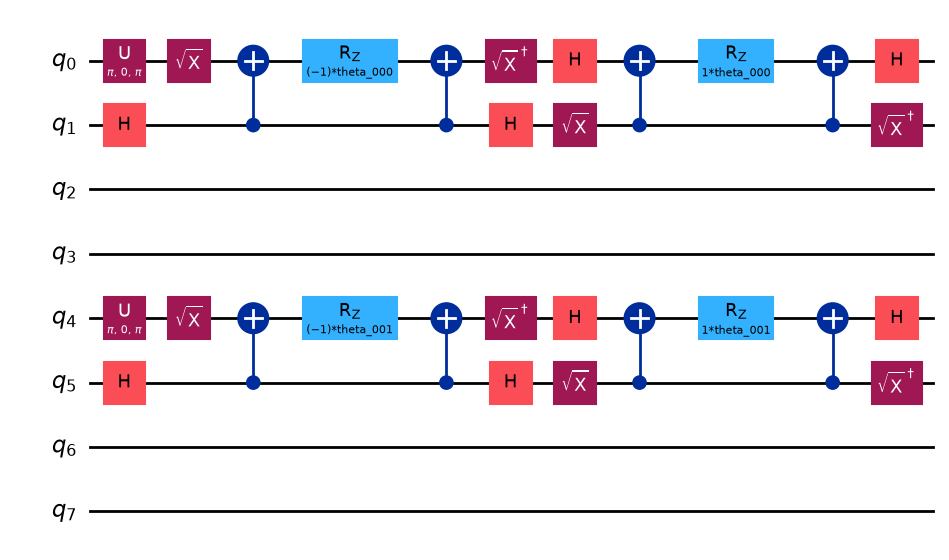

HEA + reference start for the deuteron in the Jordan-Wigner mapping (8 qubits):


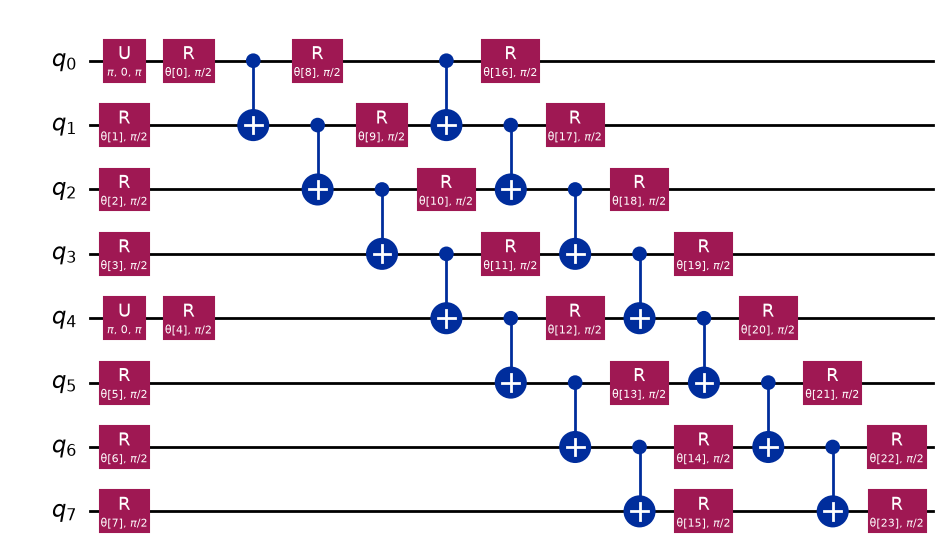

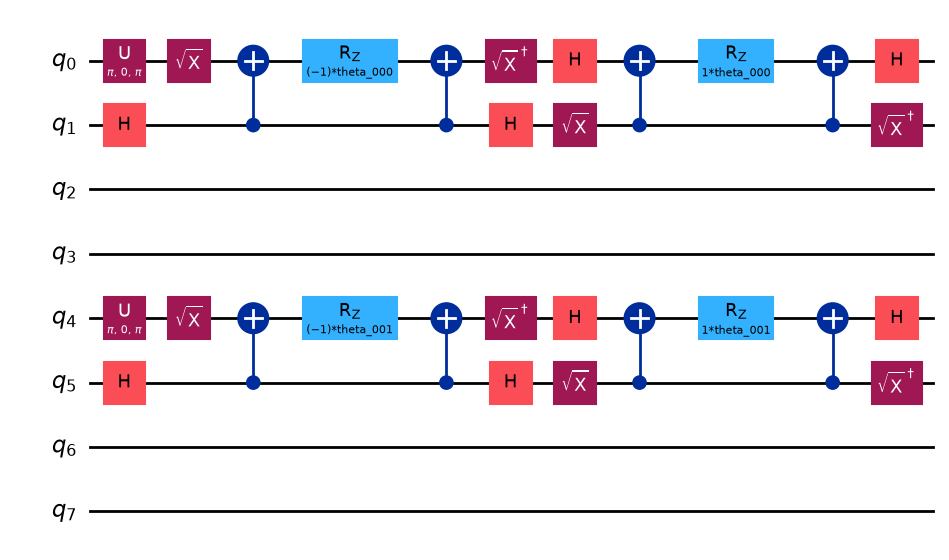

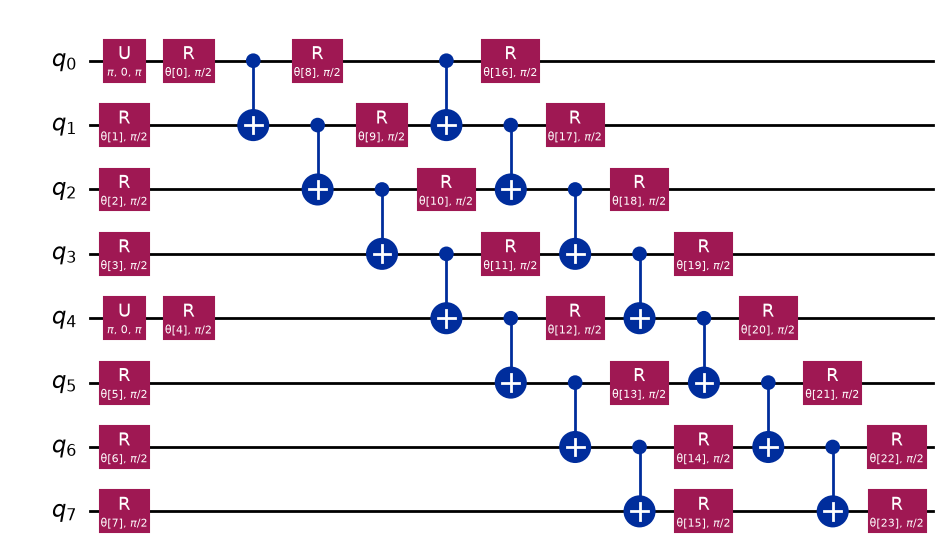

In [7]:
for name in ["uccs", "hea_ref"]:
    print(enc.LABELS[name], "for the deuteron in the Jordan-Wigner mapping (8 qubits):")
    display(enc.build_ansatz(name, 1, 1, n_orb, "jordan_wigner", reps).decompose().draw("mpl", fold=-1))

In [8]:
# Circuit cost after compiling to {RZ, SX, X, CX}, per ansatz and mapping.
print(f"{'':>13}" + "".join(f"{a:>16}" for a in enc.ANSATZES))
for mapping in ops.MAPPINGS:
    cells = []
    for name in enc.ANSATZES:
        c = enc.build_ansatz(name, z, n, n_orb, mapping, reps)
        depth, cx = enc.circuit_cost(c)
        cells.append(f"{cx:>4} CX, d={depth:<4}")
    print(f"{mapping:>13}" + "".join(f"{x:>16}" for x in cells))

                          ref            uccs           uccsd         hea_ref


jordan_wigner    0 CX, d=1      16 CX, d=18    265 CX, d=414    14 CX, d=23  
       parity    0 CX, d=1      14 CX, d=29    242 CX, d=421    14 CX, d=23  


## Stop and think: what did the encoding decide?

1. **Doubles are expensive.** Each pair move is an evolution under eight Pauli strings that touch four orbitals, and the Z strings between them make the circuit long. `uccsd` costs about 15 times more CX gates than `uccs`, and 20 times more than the hardware-efficient circuit, which is why UCC ansatzes are hard to run on today's noisy hardware.
2. **What the doubles add.** Without them the best the circuit can do is a state in which the nucleons are independent. The leftover is the **correlation energy**, and Step 4 measures how large it is in this model. The ansatz must be able to express whatever correlation is there, or no amount of optimizing will find it.
3. **`hea_ref` can leave the sector.** Its gates act on any qubit, so it can create and destroy nucleons. That is why the Hamiltonian carries the penalty: without it the optimizer would wander into states with more nucleons, where the attraction is stronger, and report an energy that is not the nucleus we asked for. The penalty gives the optimizer a steep wall but also a rough landscape.
4. **The mapping changes the circuit, not the sector.** In parity the reference state looks different (running sums) and the strings have another shape, but the moves are the same moves. The code builds each one from fermion operators, so it works in any mapping.

## Step 3: Execution

Each iteration of the VQE loop:

1. The classical optimizer (**COBYLA**) proposes angles $\boldsymbol\theta$.
2. The **Estimator** prepares $|\psi(\boldsymbol\theta)\rangle$ and returns $\langle H\rangle$, with the penalty included.
3. The optimizer lowers $\langle H\rangle$ and repeats.

Every (mapping, ansatz) pair gets the same budget (`starts` random starting points, `maxiter` iterations each) and the same random seed, so that differences come from the pair and not from the settings. `ref` has no angles and is evaluated once. For helium-4 on the simulator with exact energies the table takes a few minutes, mostly for the deep `uccsd` circuits.

In [9]:
data = execution.run(
    z,
    n,
    n_orb,
    ops.MAPPINGS,
    enc.ANSATZES,
    backend_name,
    reps=reps,
    starts=starts,
    shots=shots,
    maxiter=maxiter,
)
print(f"\nTotal time: {data['seconds']:.0f} s")

4He in 2 oscillator states per nucleon: exact energy -16.116761 MeV, reference -13.119487 MeV


  jordan_wigner     ref: error +3.00e+00 MeV (0 angles, 1 evaluations)


  jordan_wigner    uccs: error +3.79e-03 MeV (4 angles, 306 evaluations)


  jordan_wigner   uccsd: error +3.18e-05 MeV (10 angles, 776 evaluations)


  jordan_wigner hea_ref: error +2.27e+00 MeV (24 angles, 1500 evaluations)
         parity     ref: error +3.00e+00 MeV (0 angles, 1 evaluations)


         parity    uccs: error +3.79e-03 MeV (4 angles, 275 evaluations)


         parity   uccsd: error +3.18e-05 MeV (10 angles, 781 evaluations)


         parity hea_ref: error +4.01e-03 MeV (24 angles, 1500 evaluations)

Total time: 148 s


## Step 4: Analysis

Each row of the table is one pair. The **error** is the energy found minus the exact energy in this basis. It is never negative, apart from shot noise. `*` marks results within 10 keV.

The figure has two rows:

- Top row: the energy error of the best restart against the number of energy evaluations, one panel per mapping.
- Bottom row: the final energy error of every pair. The dashed line marks 10 keV.


4He (Z=2, N=2) in 2 oscillator states per nucleon on aer_simulator, exact energies
Exact energy in this basis:   -16.116761 MeV (16 states in the sector)
Reference energy:             -13.119487 MeV
Unbound nucleons:             12.864056 MeV
Binding energy in this model: 28.981 MeV

      mapping  ansatz qubits terms angles    CX  depth  evals  error (keV)
jordan_wigner     ref      8    27      0     0      1      1    2997.275 
jordan_wigner    uccs      8    27      4    16     18    306       3.788*
jordan_wigner   uccsd      8    27     10   265    414    776       0.032*
jordan_wigner hea_ref      8    27     24    14     23   1500    2271.406 
       parity     ref      8    27      0     0      1      1    2997.275 
       parity    uccs      8    27      4    14     29    275       3.788*
       parity   uccsd      8    27     10   242    421    781       0.032*
       parity hea_ref      8    27     24    14     23   1500       4.008*
* = within 10 keV of the exact energy



Saved /tmp/nuclei_result.png


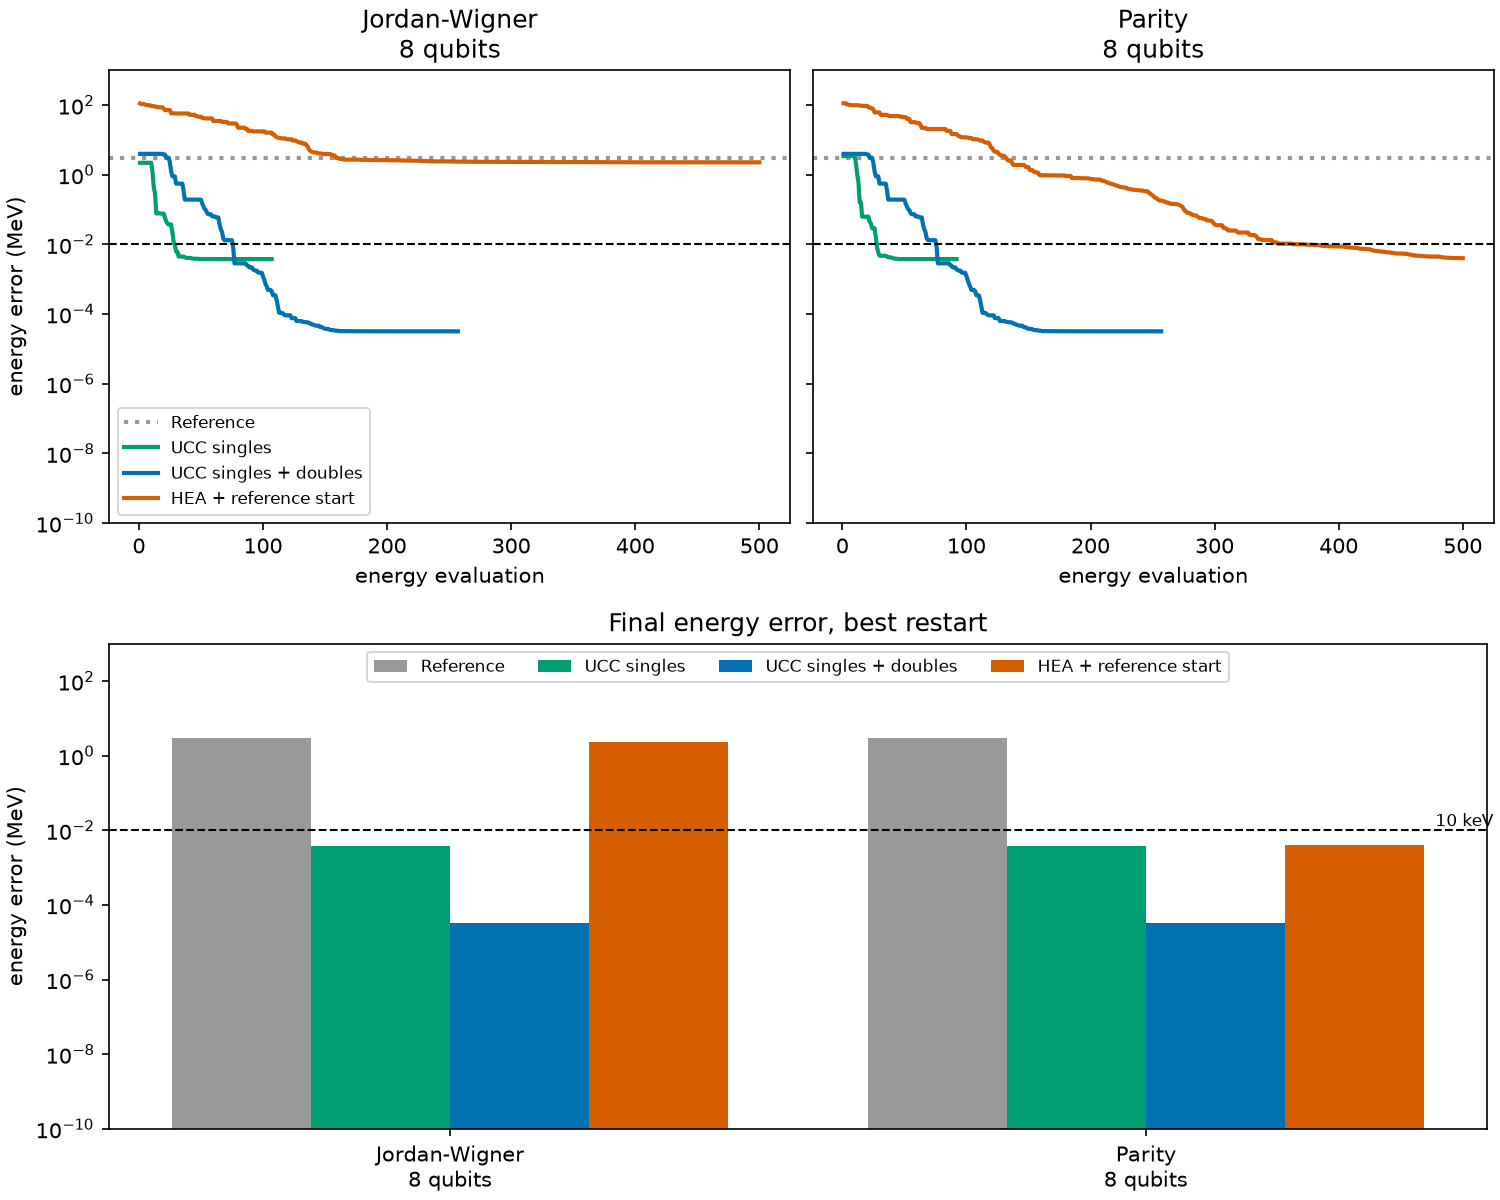

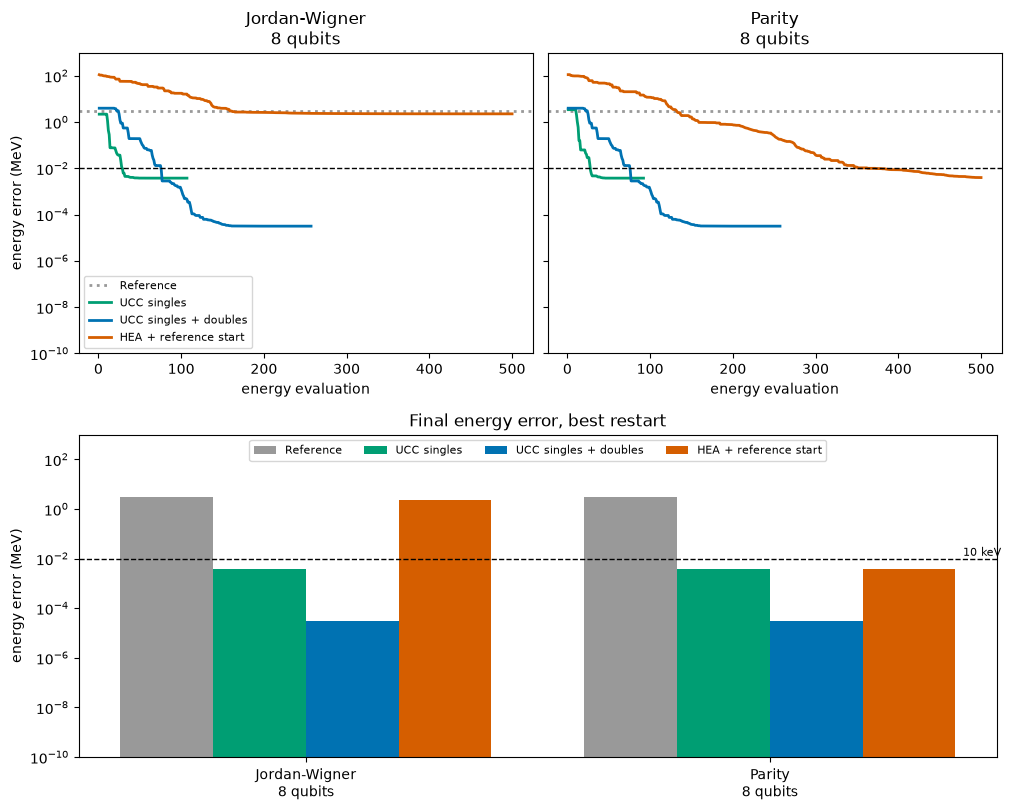

In [10]:
out = Path(tempfile.gettempdir()) / "nuclei_result.png"
analysis.analyze(data, out)
Image(out)

## Reading the results

The numbers below are for the default settings: helium-4, `n_orb = 2`, `maxiter = 500` and seed 1. Another nucleus or seed changes them.

- **`ref`**, the gray line, sits 3.0 MeV above the answer in both mappings, about a tenth of the binding energy. It never improves because it has no angles.
- **`uccs`**, in green, gets within 4 keV with four angles and 14 to 16 CX gates, in both mappings. This is the important result: letting each nucleon move to the other oscillator state already captures nearly all of the energy. The reason is the model. The contact force acts on $|0\rangle$ alone and the basis has only two states, so there is little for the nucleons to correlate about. A realistic force and a larger basis would leave a larger gap between the singles and the exact energy.
- **`uccsd`**, in blue, reaches the exact energy to better than 0.1 keV with 10 angles, in both mappings. The last 4 keV cost about 250 CX gates (15 times as many as `uccs`) and 2.5 times as many energy evaluations. Whether that is worth it depends on the accuracy you need, and on whether the hardware can run a circuit that deep.
- **`hea_ref`**, in orange, depends on the mapping. In the Jordan-Wigner form it stalls 2.3 MeV above the answer, close to `ref`; in the parity form it reaches 4 keV with 14 CX gates. It is the same circuit, so the difference comes from what the qubits mean: the Hamiltonian and its penalty look different in the two mappings, and so does the landscape the optimizer sees. One run does not say which mapping is better for this ansatz. Try other seeds and nuclei before drawing a conclusion.
- **The mapping matters little for the UCC ansatzes** here: the same angles, the same errors, and CX counts and depths of the same order (`uccs`: 16 CX at depth 18 in Jordan-Wigner against 14 CX at depth 29 in parity). With 8 qubits and neighbors that interact, no Z string gets long. The mapping becomes a real choice when the orbitals are many and the interacting ones far apart.

The ansatz that keeps the physics (here, the nucleon numbers) beats the one that is shallow and generic, as in the deuteron. The new lesson is that physical structure also keeps the optimizer inside the sector, so no penalty is needed for it to work.

## From the deuteron to helium

So far we fixed one nucleus. The point of the second-quantized recipe is that **the same code runs any nucleus**: only $Z$ and $N$ change. We run `ref`, `uccs` and `uccsd` in the Jordan-Wigner mapping for the deuteron, tritium and helium-4, and plot the **binding energy** (the energy of the unbound nucleons minus the energy found, so larger means more bound) with the measured values.

In [11]:
backend, estimator, session = execution.get_primitives(backend_name)
names = ["2H", "3H", "4He"]
curves = {"exact": [], "ref": [], "uccs": [], "uccsd": []}
for name in names:
    zz, nn = ops.parse_nucleus(name)
    ex = ops.exact_energies(n_orb, zz, nn)
    curves["exact"].append(ex["free"] - ex["exact"])
    curves["ref"].append(ex["free"] - ex["ref"])
    for ansatz in ("uccs", "uccsd"):
        rec = execution.optimize(
            zz, nn, n_orb, "jordan_wigner", ansatz, estimator, backend,
            reps, starts=2, shots=shots, maxiter=maxiter,
        )
        curves[ansatz].append(ex["free"] - rec["energy"])
if session is not None:
    session.close()

print(f"{'nucleus':>7} {'qubits':>6} {'exact':>8} {'ref':>8} {'uccs':>8} {'uccsd':>8}   (binding energy, MeV)")
for k, name in enumerate(names):
    print(f"{name:>7} {ops.n_modes(n_orb):>6}" + "".join(f"{curves[key][k]:>9.3f}" for key in curves))

nucleus qubits    exact      ref     uccs    uccsd   (binding energy, MeV)
     2H      8    4.297    1.619    4.288    4.297
     3H      8   13.856   10.958   13.850   13.856
    4He      8   28.981   25.984   28.977   28.981


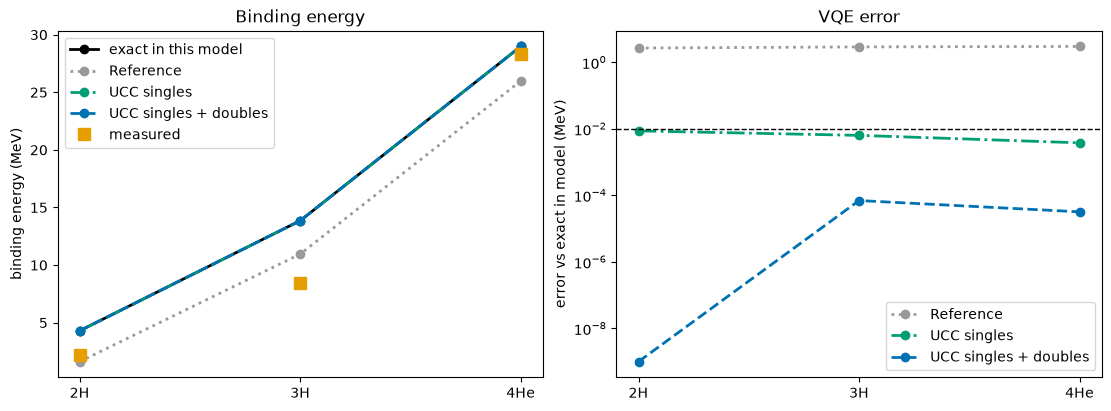

In [12]:
fig = analysis.plot_nuclei_scan(names, curves, experiment=[measured[name] for name in names])

## Stop and think: what did the scan show?

1. **The same recipe worked for three nuclei.** The only inputs that changed were $Z$ and $N$. The sector gets larger (4, 8 and 16 states), but the register stays at 8 qubits, because the orbitals are the same.
2. **The reference misses by about 3 MeV each time**, which is 62% of the deuteron's binding, 21% of tritium's and 10% of helium-4's. The moves recover this with little effort. `uccs` ends 4 to 9 keV below the exact binding energy and `uccsd` is exact to the plotted precision.
3. **Modeling and computational errors, again.** The VQE errors are all in keV, but the model's binding energies are not the measured ones: 4.3 against 2.2 MeV for the deuteron, 13.9 against 8.5 MeV for tritium, 29.0 against 28.3 MeV for helium-4. The model overbinds the light nuclei because every pair of nucleons in $|0\rangle$ attracts equally, whereas in nature the force depends on spin and isospin and only the deuteron pair is bound. Making the circuit better would not fix that; a better Hamiltonian would.
4. **What is not in the plot.** The circuit gets deeper and the optimizer slower with every nucleon (the doubles grow like the number of pairs). The sector, which the quantum computer explores, grows much faster than the number of qubits. That is the reason the problem is a candidate for a quantum computer, and why real nuclear calculations need many more orbitals, $P$-wave states and a force with spin.
5. **Everything here is noiseless and exact.** Set `shots = 4096` in Setup and rerun from Step 3: the standard error of $1/\sqrt{4096}\approx 0.016$ MeV is larger than the 10 keV target, and the deep `uccsd` circuit would also collect gate noise on hardware.

## What to try next

1. Set `nucleus = "3He"` and compare with `"3H"`. They have the same energy in the model. Which term would you add to the Hamiltonian to separate them (hint: the Coulomb repulsion between protons is a two-body term $\propto n_{p}n_{p'}$)?
2. Try `nucleus = "2,2"` with `n_orb = 3`: 12 qubits and a sector of 81 states. Does the gap between `uccs` and `uccsd` grow with the basis? (It takes several minutes.)
3. Run a nucleus with $A > 4$, such as `"3,3"` (lithium-6) with `n_orb = 3`. The reference now has nucleons in $|1\rangle$. What happens to the binding energy per nucleon, and why does a model with only S-wave states fail here? (A real calculation adds P-wave orbitals.)
4. Change the orbital order in `ops.mode` so that all four kinds of one oscillator state are neighbors ($p$ major, kind minor). How do the Jordan-Wigner terms and CX counts change?
5. Set `shots = 4096` and look at the final error. Which ansatzes still end within 10 keV, and how does the size of the penalty (30 MeV) enter the noise on the energy of `hea_ref`?
6. Remove the penalty (set `PENALTY = 0` in `ops.py`) and rerun `hea_ref`. What energy does it report, and which nucleus does that state describe?
7. Change `V0` or break the SU(4) symmetry by giving the proton-neutron pairs a different strength than the like-nucleon pairs in `build_hamiltonian`. Does the dineutron stay bound as the deuteron does?
8. Compare with the deuteron notebook: that one used $\log_2 N$ qubits to store one particle in $N$ states. Here the register is $4\,n_\text{orb}$ qubits. At which $A$ does the orbital description beat a single wave function of $A$ coordinates on a grid?